# Lake Kariba night lights: DBSCAN model

This notebook starts from the **cleaned** data produced by `kariba_data_cleaning.ipynb` and builds the detection model.

DBSCAN is **unsupervised**: there are no labels saying "this light was illegal fishing". "Training" here means:

1. **choosing the DBSCAN settings** (`eps`, the neighbourhood distance, and `min_samples`, the smallest group) from the data itself;
2. **learning what normal looks like**: a baseline light level for every zone and moon band, from the training period;
3. **testing on later nights** the model has not seen: flagging zone-nights that are far brighter than their baseline, and turning their clusters into alerts.

The outputs match the backend tables: zone light readings, zone baselines, alerts, and suggested zone settings.

| Step | Section |
|---|---|
| Load the cleaned data and the zones | 2–5 |
| Split by time into training and test nights | 6 |
| Choose `eps` and `min_samples` | 7–8 |
| Cluster every night | 9 |
| Build nightly readings per zone | 10 |
| Learn baselines per zone and moon band | 11 |
| Score nights and raise alerts | 12–13 |
| Evaluate | 14 |
| Save the model outputs | 15 |

## 1. Libraries

- `pandas`, `numpy`: tables and numbers.
- `sklearn.cluster.DBSCAN`: the clustering.
- `sklearn.neighbors.BallTree`: fast nearest-neighbour distances on the globe (haversine), used to choose `eps`.
- `sklearn.metrics.silhouette_score`: how well separated the clusters are.
- `matplotlib.path.Path`: tests which zone a point is in.
- `matplotlib.pyplot`: charts.

In [ ]:
import json
import math
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.path import Path as Outline
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import BallTree

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 2. Settings

| Setting | Meaning |
|---|---|
| `CLEAN_FOLDER` | where `kariba_clean_points.csv` and `kariba_nightly_qc.csv` are |
| `ZONES_FILE` | the zones JSON (the same file the backend imports) |
| `MODEL_FOLDER` | where the model outputs are saved |
| `EXCLUDE_NEAR_SHORE` | leave out points flagged as possible town glow |
| `TEST_FROM` | nights from this date on are the **test** set, never used for choosing settings or baselines |
| `MIN_SAMPLES_GRID`, `EPS_GRID_KM` | the DBSCAN settings tried |
| `MAX_NOISE_SHARE` | a setting is rejected if more than this share of points end up as noise |
| `ALERT_K_MAD` | a zone-night is anomalous when it is this many robust deviations above its baseline |
| `MIN_MAD_SHARE` | the smallest spread allowed, as a share of the baseline, so a zone that is almost always dark does not alert on one lamp |

In [ ]:
CLEAN_FOLDER = Path.home() / "kariba-cleaning" / "out"
ZONES_FILE = Path.home() / "kariba_zone_and_basins" / "kariba_zones.json"
MODEL_FOLDER = Path.home() / "kariba-cleaning" / "model"

EXCLUDE_NEAR_SHORE = True
TEST_FROM = "2021-07-01"
MIN_SAMPLES_GRID = (3, 4, 5, 6)
EPS_GRID_KM = (0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0)
MAX_NOISE_SHARE = 0.4
ALERT_K_MAD = 3.0
MIN_MAD_SHARE = 0.25

EARTH_RADIUS_KM = 6371.0088
SYNODIC_MONTH_DAYS = 29.530588853
REFERENCE_NEW_MOON = datetime(2000, 1, 6, 18, 14, tzinfo=timezone.utc)

MODEL_FOLDER.mkdir(parents=True, exist_ok=True)
print("Clean data:", CLEAN_FOLDER, "| exists:", CLEAN_FOLDER.exists())
print("Zones file:", ZONES_FILE, "| exists:", ZONES_FILE.exists())
print("Model outputs:", MODEL_FOLDER)

Clean data: /home/Student/kariba-cleaning/out | exists: True
Zones file: /home/Student/kariba_zone_and_basins/kariba_zones.json | exists: True
Model outputs: /home/Student/kariba-cleaning/model


## 3. Load the cleaned data

- `points`: one row per light per night, from the cleaning notebook.
- `nights`: every **analysed** night from the quality report. This matters: a clear night with no lights in a zone is a real observation of "quiet", and the baselines must count it as zero. Skipped (cloudy) nights are not observations and are left out.
- Near-shore points are removed when `EXCLUDE_NEAR_SHORE` is on.

In [ ]:
points = pd.read_csv(CLEAN_FOLDER / "kariba_clean_points.csv", parse_dates=["Date"])
quality = pd.read_csv(CLEAN_FOLDER / "kariba_nightly_qc.csv")
nights = pd.to_datetime(quality.loc[quality["Status"] == "analysed", "Date"]).drop_duplicates().sort_values().reset_index(drop=True)

before = len(points)
if EXCLUDE_NEAR_SHORE:
    points = points[~points["Near_Shore"].astype(bool)]
points = points[points["Date"].isin(nights)].reset_index(drop=True)

print(f"Points: {len(points)} (removed {before - len(points)} near-shore or from unanalysed nights)")
print(f"Analysed nights: {len(nights)} from {nights.min().date()} to {nights.max().date()}")

Points: 78405 (removed 25169 near-shore or from unanalysed nights)
Analysed nights: 710 from 2019-01-23 to 2021-12-29


## 4. Which zone is each point in?

Each point is tested against the zone polygons. Points on the lake but outside every zone are kept as `Outside zones`: they still count for clustering, but they do not feed any zone's baseline.

In [ ]:
zones = json.loads(ZONES_FILE.read_text(encoding="utf-8"))["zones"]
ZONE_NAMES = [zone["name"] for zone in zones]
OUTSIDE = "Outside zones"


def zone_of(longitudes, latitudes):
    found = np.full(len(longitudes), OUTSIDE, dtype=object)
    coordinates = np.column_stack([longitudes, latitudes])
    for zone in zones:
        rings = zone["boundary"]["coordinates"]
        inside = Outline(np.asarray(rings[0])).contains_points(coordinates)
        for hole in rings[1:]:
            inside &= ~Outline(np.asarray(hole)).contains_points(coordinates)
        found[inside & (found == OUTSIDE)] = zone["name"]
    return found


points["Zone"] = zone_of(points["Longitude"].to_numpy(), points["Latitude"].to_numpy())
print(points["Zone"].value_counts().to_string())

Zone
Outside zones    64443
Zone 7            3567
Zone 5            2988
Zone 1            2121
Zone 3            1132
Zone 2            1126
Zone 4            1109
Zone 8            1013
Zone 6             906


## 5. Moon band of each night

Moonlight brightens the water and changes how much fishing happens (kapenta fishing is lighter around full moon), so each night gets a moon band: **dark** (under 25% lit), **partial**, or **bright** (75% or more).

This is the same calculation the backend's baseline service uses, so the notebook and the system agree.

In [ ]:
def moon_illumination(day):
    moment = datetime(day.year, day.month, day.day, 22, tzinfo=timezone.utc)
    age = ((moment - REFERENCE_NEW_MOON).total_seconds() / 86400) % SYNODIC_MONTH_DAYS
    return (1 - math.cos(2 * math.pi * age / SYNODIC_MONTH_DAYS)) / 2


def moon_band(day):
    value = moon_illumination(day)
    if value < 0.25:
        return "dark"
    if value < 0.75:
        return "partial"
    return "bright"


night_table = pd.DataFrame({"Date": nights})
night_table["Moon_Band"] = night_table["Date"].map(moon_band)
points = points.merge(night_table, on="Date", how="left")
print(night_table["Moon_Band"].value_counts().to_string())

Moon_Band
partial    242
dark       240
bright     228


## 6. Training and test nights

The split is **by time**, not at random: the model learns from earlier nights and is tested on later ones, the same way it will be used. Random splitting would let the model peek at the future.

In [ ]:
night_table["Set"] = np.where(night_table["Date"] < pd.Timestamp(TEST_FROM), "train", "test")
points = points.merge(night_table[["Date", "Set"]], on="Date", how="left")
print(night_table["Set"].value_counts().to_string())
print(f"Training nights end {night_table.loc[night_table['Set'] == 'train', 'Date'].max().date()}, test nights start {TEST_FROM}")

Set
train    581
test     129
Training nights end 2021-06-30, test nights start 2021-07-01


## 7. Choosing `eps` from the data (k-distance)

For every training point, the distance to its *k*-th nearest neighbour on the same night is measured (k = the middle `min_samples` value). Sorted, these distances bend sharply where points stop being in groups and start being isolated. The **knee** of that curve is a natural `eps`: closer than that, points belong together.

The knee is found as the point on the curve furthest from the straight line joining its ends (the "kneedle" idea). The 99th percentile is used as the end so a few far-away points do not flatten the curve.

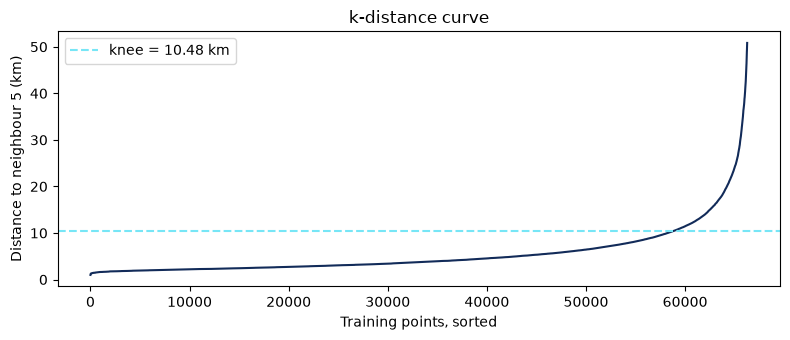

Suggested eps from the knee: 10.48 km


In [ ]:
K_FOR_EPS = MIN_SAMPLES_GRID[len(MIN_SAMPLES_GRID) // 2]
distances = []
for _, night in points[points["Set"] == "train"].groupby("Date"):
    if len(night) <= K_FOR_EPS:
        continue
    coordinates = np.radians(night[["Latitude", "Longitude"]].to_numpy())
    found, _ = BallTree(coordinates, metric="haversine").query(coordinates, k=K_FOR_EPS + 1)
    distances.append(found[:, -1] * EARTH_RADIUS_KM)

k_distance = np.sort(np.concatenate(distances))
k_distance = k_distance[k_distance <= np.percentile(k_distance, 99)]
x = np.linspace(0, 1, len(k_distance))
y = (k_distance - k_distance[0]) / (k_distance[-1] - k_distance[0])
knee = int(np.argmax(x - y))
KNEE_EPS_KM = float(k_distance[knee])

plt.figure(figsize=(8, 3.5))
plt.plot(k_distance, color="#122B59")
plt.axhline(KNEE_EPS_KM, color="#77E6F6", linestyle="--", label=f"knee = {KNEE_EPS_KM:.2f} km")
plt.xlabel("Training points, sorted")
plt.ylabel(f"Distance to neighbour {K_FOR_EPS} (km)")
plt.title("k-distance curve")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Suggested eps from the knee: {KNEE_EPS_KM:.2f} km")

## 8. Testing the settings on training nights

Every combination of `eps` and `min_samples` is run on every training night and measured:
- **Noise share**: points left out of all clusters. Too high means the setting is too strict.
- **Clusters per night**.
- **Silhouette** (from −1 to 1): how tight and well separated the clusters are, using real distances on the globe. Higher is better.

**Choice rule:** among settings with noise share at or below `MAX_NOISE_SHARE`, take the highest silhouette; if several are within 0.01 of it, take the **smallest `eps`**, then the closest to the knee. A smaller distance keeps two nearby fleets as two clusters instead of merging them into one. The rule is written down so the choice can be explained and repeated.

In [ ]:
def run_dbscan(night, eps_km, min_samples):
    coordinates = np.radians(night[["Latitude", "Longitude"]].to_numpy())
    if len(coordinates) < min_samples:
        return np.full(len(coordinates), -1)
    return DBSCAN(eps=eps_km / EARTH_RADIUS_KM, min_samples=min_samples, metric="haversine", algorithm="ball_tree").fit_predict(coordinates)


train_nights = [night for _, night in points[points["Set"] == "train"].groupby("Date")]
grid_rows = []
for eps_km in EPS_GRID_KM:
    for min_samples in MIN_SAMPLES_GRID:
        noise, total, clusters, scores = 0, 0, 0, []
        for night in train_nights:
            labels = run_dbscan(night, eps_km, min_samples)
            noise += int((labels == -1).sum())
            total += len(labels)
            found = set(labels) - {-1}
            clusters += len(found)
            kept = labels != -1
            if len(found) >= 2 and kept.sum() > len(found):
                coordinates = np.radians(night[["Latitude", "Longitude"]].to_numpy())[kept]
                scores.append(silhouette_score(coordinates, labels[kept], metric="haversine"))
        grid_rows.append({
            "eps_km": eps_km,
            "min_samples": min_samples,
            "noise_share": round(noise / total, 3) if total else np.nan,
            "clusters_per_night": round(clusters / len(train_nights), 2),
            "silhouette": round(float(np.mean(scores)), 3) if scores else np.nan,
        })

grid = pd.DataFrame(grid_rows)
allowed = grid[(grid["noise_share"] <= MAX_NOISE_SHARE) & grid["silhouette"].notna()].copy()
if allowed.empty:
    allowed = grid[grid["silhouette"].notna()].copy()
best_score = allowed["silhouette"].max()
close = allowed[allowed["silhouette"] >= best_score - 0.01].copy()
close["distance_to_knee"] = (close["eps_km"] - KNEE_EPS_KM).abs()
chosen = close.sort_values(["eps_km", "distance_to_knee"]).iloc[0]
EPS_KM = float(chosen["eps_km"])
MIN_SAMPLES = int(chosen["min_samples"])

display(grid.pivot(index="eps_km", columns="min_samples", values="silhouette"))
display(grid.pivot(index="eps_km", columns="min_samples", values="noise_share"))
print(f"Chosen: eps = {EPS_KM} km, min_samples = {MIN_SAMPLES} (silhouette {chosen['silhouette']}, noise {chosen['noise_share']})")

min_samples,3,4,5,6
eps_km,,,,
0.50,NaN,NaN,NaN,NaN
0.75,NaN,NaN,NaN,NaN
1.00,0.832,0.892,0.993,NaN
1.50,0.714,0.745,0.813,0.855
2.00,0.710,0.737,0.763,0.797
3.00,0.690,0.709,0.732,0.753
5.00,0.664,0.674,0.689,0.708


min_samples,3,4,5,6
eps_km,,,,
0.50,1.000,1.000,1.000,1.000
0.75,1.000,1.000,1.000,1.000
1.00,0.914,0.986,0.999,1.000
1.50,0.501,0.705,0.874,0.962
2.00,0.342,0.491,0.628,0.762
3.00,0.211,0.297,0.388,0.477
5.00,0.103,0.151,0.199,0.250


Chosen: eps = 3.0 km, min_samples = 5 (silhouette 0.732, noise 0.388)


## 9. Clustering every night

DBSCAN is run on each night separately with the chosen settings: a light on Monday and a light on Tuesday are not the same observation, so cluster numbers restart every night.

Each cluster is summarised: how many points, its centre, its brightest and average radiance, its size (the furthest point from the centre), and the zone most of its points are in.

In [ ]:
labelled = []
for _, night in points.groupby("Date"):
    labelled.append(night.assign(Cluster_ID=run_dbscan(night, EPS_KM, MIN_SAMPLES)))
points = pd.concat(labelled, ignore_index=True)


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))


in_clusters = points[points["Cluster_ID"] >= 0]
clusters = (
    in_clusters.groupby(["Date", "Cluster_ID"])
    .agg(
        Points=("Radiance", "size"),
        Centroid_Lat=("Latitude", "mean"),
        Centroid_Lon=("Longitude", "mean"),
        Max_Radiance=("Radiance", "max"),
        Mean_Radiance=("Radiance", "mean"),
        Zone=("Zone", lambda values: values.mode().iloc[0]),
        Set=("Set", "first"),
        Moon_Band=("Moon_Band", "first"),
    )
    .reset_index()
)
centres = in_clusters.merge(clusters[["Date", "Cluster_ID", "Centroid_Lat", "Centroid_Lon"]], on=["Date", "Cluster_ID"])
centres["Distance_km"] = haversine_km(centres["Latitude"], centres["Longitude"], centres["Centroid_Lat"], centres["Centroid_Lon"])
clusters = clusters.merge(centres.groupby(["Date", "Cluster_ID"])["Distance_km"].max().rename("Radius_km").reset_index(), on=["Date", "Cluster_ID"])

print(f"Clusters found: {len(clusters)} on {clusters['Date'].nunique()} nights")
print(f"Points in clusters: {len(in_clusters)} of {len(points)} ({len(in_clusters) / len(points):.0%})")
display(clusters.head(10))

Clusters found: 3824 on 517 nights
Points in clusters: 47248 of 78405 (60%)


,Date,Cluster_ID,Points,Centroid_Lat,Centroid_Lon,Max_Radiance,Mean_Radiance,Zone,Set,Moon_Band,Radius_km
0,2019-01-23,0,12,-17.899132,27.124479,3.8119,2.536942,Outside zones,train,bright,4.289306
1,2019-01-23,1,31,-17.672581,27.310820,3.2688,2.509126,Zone 7,train,bright,8.027131
2,2019-01-23,2,12,-16.705498,28.879398,3.1076,2.558417,Outside zones,train,bright,3.798132
3,2019-01-23,3,6,-16.747801,28.538889,3.0536,2.491700,Zone 3,train,bright,2.604995
4,2019-01-23,4,8,-16.693489,28.954948,2.9717,2.621975,Outside zones,train,bright,2.964569
5,2019-01-23,5,25,-17.348278,27.570695,2.8290,2.476936,Outside zones,train,bright,5.887249
6,2019-01-23,6,9,-16.943750,28.093981,2.7150,2.407844,Outside zones,train,bright,3.859097
7,2019-01-23,7,7,-17.404464,27.516369,2.5459,2.287814,Outside zones,train,bright,3.905848
8,2019-01-23,8,7,-17.950893,27.017262,2.5016,2.438129,Outside zones,train,bright,3.236965
9,2019-01-23,9,18,-16.820679,28.205942,2.2390,2.049556,Outside zones,train,bright,6.025738


## 10. Nightly readings per zone

This turns points and clusters into one row per **zone per analysed night**, the same shape as the backend's `zone_light_reading` table:
- `Light_Index`: total radiance of all lights in the zone that night;
- `Hotspot_Count`: number of lights;
- `Cluster_Count`: number of DBSCAN clusters centred in the zone.

Clear nights with no lights in a zone get zeros, so quiet nights are part of what "normal" looks like.

In [ ]:
grid_index = pd.MultiIndex.from_product([night_table["Date"], ZONE_NAMES], names=["Date", "Zone"])
zoned = points[points["Zone"] != OUTSIDE]
readings = (
    zoned.groupby(["Date", "Zone"]).agg(Light_Index=("Radiance", "sum"), Hotspot_Count=("Radiance", "size"))
    .reindex(grid_index, fill_value=0)
    .reset_index()
)
cluster_counts = clusters[clusters["Zone"] != OUTSIDE].groupby(["Date", "Zone"]).size().rename("Cluster_Count")
readings = readings.merge(cluster_counts.reset_index(), on=["Date", "Zone"], how="left").fillna({"Cluster_Count": 0})
readings = readings.merge(night_table, on="Date", how="left")
readings["Cluster_Count"] = readings["Cluster_Count"].astype(int)
print(f"Zone-night readings: {len(readings)} ({len(ZONE_NAMES)} zones x {len(night_table)} nights)")
display(readings.groupby(["Zone", "Moon_Band"])["Light_Index"].median().unstack().round(1))

Zone-night readings: 5680 (8 zones x 710 nights)


Moon_Band,bright,dark,partial
Zone,,,
Zone 1,10.1,1.8,2.0
Zone 2,10.3,0.0,0.0
Zone 3,5.7,0.0,0.0
Zone 4,3.7,0.0,0.0
Zone 5,11.9,1.6,2.2
Zone 6,1.6,0.0,0.0
Zone 7,21.1,0.0,0.0
Zone 8,2.4,0.0,0.0


## 11. Baselines: what normal looks like

From the **training** nights only, for every zone and moon band:
- `Expected_Light_Index`: the **median** light index (robust: a few very busy nights do not move it much);
- `Spread`: the robust spread, 1.4826 × the median absolute deviation, with a minimum of `MIN_MAD_SHARE` × the median (and at least 1) so a zone that is nearly always dark does not alert on a single lamp;
- `Nights_Used`: how many nights it was based on.

This is the same idea as the backend's `zone_baseline` table, and the medians can be loaded into it.

In [ ]:
train_readings = readings[readings["Set"] == "train"]
baselines = (
    train_readings.groupby(["Zone", "Moon_Band"])["Light_Index"]
    .agg(
        Expected_Light_Index="median",
        MAD=lambda values: float(np.median(np.abs(values - np.median(values)))),
        Nights_Used="size",
    )
    .reset_index()
)
baselines["Spread"] = np.maximum.reduce([
    1.4826 * baselines["MAD"],
    MIN_MAD_SHARE * baselines["Expected_Light_Index"],
    np.ones(len(baselines)),
])
display(baselines.round(2))

,Zone,Moon_Band,Expected_Light_Index,MAD,Nights_Used,Spread
0,Zone 1,bright,10.56,10.56,190,15.66
1,Zone 1,dark,1.91,1.91,194,2.83
2,Zone 1,partial,2.11,2.11,197,3.12
3,Zone 2,bright,10.27,10.27,190,15.23
4,Zone 2,dark,0.00,0.00,194,1.00
5,Zone 2,partial,0.00,0.00,197,1.00
6,Zone 3,bright,6.54,6.54,190,9.70
7,Zone 3,dark,0.00,0.00,194,1.00
8,Zone 3,partial,0.00,0.00,197,1.00
9,Zone 4,bright,4.63,4.63,190,6.86


## 12. Scoring every zone-night

Each zone-night is compared with its baseline for that moon band:

`score = (Light_Index − Expected_Light_Index) / Spread`

A zone-night is **anomalous** when the score is at least `ALERT_K_MAD` **and** it has at least one cluster. Both are needed: a bright total without any cluster is scattered lights, not a fleet.

In [ ]:
scored = readings.merge(baselines[["Zone", "Moon_Band", "Expected_Light_Index", "Spread"]], on=["Zone", "Moon_Band"], how="left")
scored["Score"] = (scored["Light_Index"] - scored["Expected_Light_Index"]) / scored["Spread"]
scored["Anomalous"] = (scored["Score"] >= ALERT_K_MAD) & (scored["Cluster_Count"] >= 1)
print(scored.groupby("Set")["Anomalous"].agg(["sum", "mean"]).rename(columns={"sum": "anomalous_zone_nights", "mean": "share"}).round(3))

       anomalous_zone_nights  share
Set                                
test                      38  0.037
train                    242  0.052


## 13. Turning anomalies into alerts

Every cluster in an anomalous zone-night becomes an **alert**, shaped like the backend's `alert` table: zone, night, cluster label, number of points, centre and a confidence.

`confidence = score / (score + ALERT_K_MAD)`: exactly at the threshold it is 0.5, and it rises towards 1 as the night gets further above normal. It is a ranking of how unusual the night is, not a probability that fishing is illegal.

In [ ]:
alert_nights = scored[scored["Anomalous"]][["Date", "Zone", "Score", "Set"]]
alerts = clusters.merge(alert_nights, on=["Date", "Zone", "Set"], how="inner")
alerts["Confidence"] = (alerts["Score"] / (alerts["Score"] + ALERT_K_MAD)).clip(upper=0.9999).round(4)
alerts = alerts.rename(columns={"Cluster_ID": "Cluster_Label", "Points": "Point_Count"})
alerts = alerts[["Date", "Zone", "Cluster_Label", "Point_Count", "Confidence", "Centroid_Lat", "Centroid_Lon", "Radius_km", "Max_Radiance", "Score", "Set"]]
alerts = alerts.sort_values(["Date", "Confidence"], ascending=[True, False]).reset_index(drop=True)

print(f"Alerts: {len(alerts)} ({(alerts['Set'] == 'test').sum()} in the test period)")
display(alerts[alerts["Set"] == "test"].head(15))

Alerts: 314 (44 in the test period)


,Date,Zone,Cluster_Label,Point_Count,Confidence,Centroid_Lat,Centroid_Lon,Radius_km,Max_Radiance,Score,Set
270,2021-07-11,Zone 6,8,6,0.7987,-17.528241,27.440393,3.558204,2.5930,11.900300,test
271,2021-07-22,Zone 7,0,38,0.6012,-17.664218,27.317781,8.848434,35.8862,4.521665,test
272,2021-07-22,Zone 3,6,10,0.5069,-16.745347,28.555972,4.193769,5.7023,3.084380,test
273,2021-07-25,Zone 5,2,10,0.6097,-17.072292,27.882083,5.355343,7.7367,4.686580,test
274,2021-07-25,Zone 3,8,7,0.5076,-16.772917,28.471428,3.157964,4.4866,3.092670,test
275,2021-07-28,Zone 6,3,6,0.6778,-17.520833,27.444444,1.930624,2.9728,6.312205,test
276,2021-08-07,Zone 6,11,5,0.7639,-17.526528,27.428333,2.496343,2.2135,9.708400,test
277,2021-08-18,Zone 6,2,9,0.6817,-17.532562,27.434568,3.952510,3.1506,6.423735,test
278,2021-08-21,Zone 6,1,9,0.8579,-17.522222,27.424768,4.371124,12.8765,18.106367,test
279,2021-08-23,Zone 4,5,12,0.6129,-16.819734,28.215451,5.944375,5.3682,4.749119,test


## 14. Evaluation

There are no labelled examples yet, so the model cannot be scored with accuracy or recall. These checks show whether it behaves sensibly; real validation comes later, when patrol inspections (`activity_consistent` / `no_activity`) are matched with the alerts.

1. **Alert rate, training vs test**: similar rates mean the baselines still describe the later period; a big jump on test nights is either a real change or drift worth investigating.
2. **Baseline stability**: baselines learned on the first and second half of the training period should agree. A high rank correlation means they are stable.
3. **Moon effect**: light index should differ by moon band, which justifies separate baselines.
4. **Where alerts happen**: alerts per zone, to spot a zone that alerts suspiciously often.

,zone_nights,anomalous,alert_rate
Set,,,
test,1032,38,0.0368
train,4648,242,0.0521


Baseline stability (Spearman, first vs second half of training): 0.76


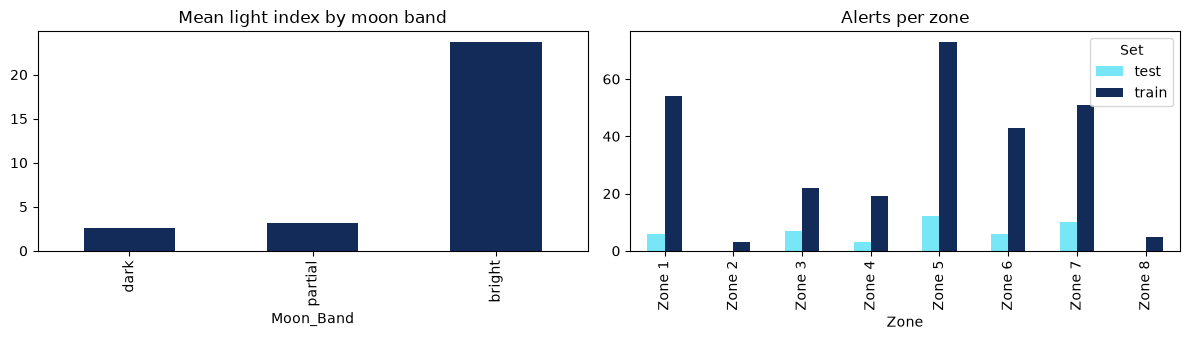

In [ ]:
rates = scored.groupby("Set").agg(zone_nights=("Anomalous", "size"), anomalous=("Anomalous", "sum"))
rates["alert_rate"] = (rates["anomalous"] / rates["zone_nights"]).round(4)
display(rates)

middle = train_readings["Date"].sort_values().iloc[len(train_readings) // 2]
halves = []
for name, part in (("first_half", train_readings[train_readings["Date"] < middle]), ("second_half", train_readings[train_readings["Date"] >= middle])):
    halves.append(part.groupby(["Zone", "Moon_Band"])["Light_Index"].median().rename(name))
stability = pd.concat(halves, axis=1).dropna()
print(f"Baseline stability (Spearman, first vs second half of training): {stability['first_half'].corr(stability['second_half'], method='spearman'):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
order = ["dark", "partial", "bright"]
readings.groupby("Moon_Band")["Light_Index"].mean().reindex(order).plot(kind="bar", ax=axes[0], color="#122B59", title="Mean light index by moon band")
alerts.groupby(["Zone", "Set"]).size().unstack(fill_value=0).reindex(ZONE_NAMES, fill_value=0).plot(kind="bar", ax=axes[1], color=["#77E6F6", "#122B59"], title="Alerts per zone")
plt.tight_layout()
plt.show()

The chart below follows one zone over time: its nightly light index, its expected level for the moon band, and the nights it alerted. It shows the reasoning behind each alert in a way a coordinator can follow.

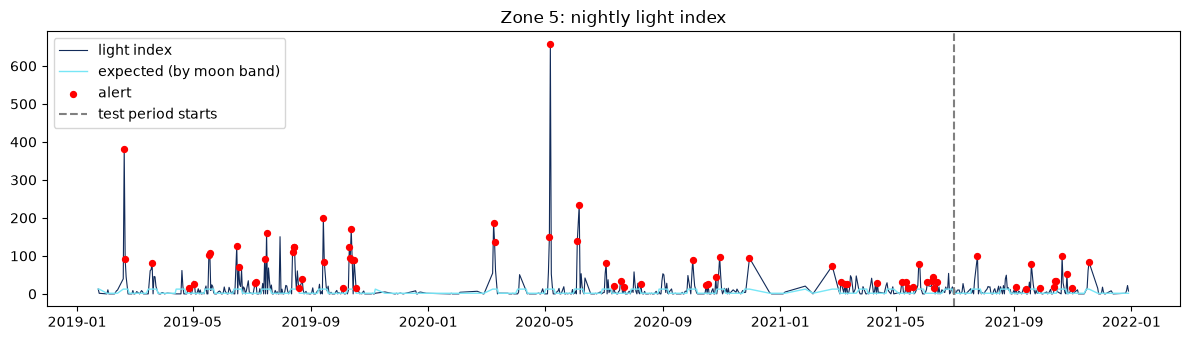

In [ ]:
if len(alerts):
    focus = alerts["Zone"].value_counts().idxmax()
    series = scored[scored["Zone"] == focus].sort_values("Date")
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(series["Date"], series["Light_Index"], color="#122B59", linewidth=0.8, label="light index")
    ax.plot(series["Date"], series["Expected_Light_Index"], color="#77E6F6", linewidth=1, label="expected (by moon band)")
    flagged = series[series["Anomalous"]]
    ax.scatter(flagged["Date"], flagged["Light_Index"], color="red", s=18, zorder=3, label="alert")
    ax.axvline(pd.Timestamp(TEST_FROM), color="grey", linestyle="--", label="test period starts")
    ax.set_title(f"{focus}: nightly light index")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 15. Save the model outputs

| File | Use |
|---|---|
| `kariba_clusters.csv` | every cluster found, every night |
| `kariba_zone_readings.csv` | one row per zone per night (backend: `zone_light_reading`) |
| `kariba_zone_baselines.csv` | expected light index per zone and moon band (backend: `zone_baseline`) |
| `kariba_alerts.csv` | alerts with confidence (backend: `alert`) |
| `kariba_model_settings.json` | the chosen settings and rules, so the backend and the report use the same numbers |

The settings file also suggests values for the backend's zone detection settings: `cluster_radius_m` from `eps` and `min_cluster_points` from `min_samples`.

In [ ]:
clusters.to_csv(MODEL_FOLDER / "kariba_clusters.csv", index=False)
readings.to_csv(MODEL_FOLDER / "kariba_zone_readings.csv", index=False)
baselines.to_csv(MODEL_FOLDER / "kariba_zone_baselines.csv", index=False)
alerts.to_csv(MODEL_FOLDER / "kariba_alerts.csv", index=False)

settings = {
    "dbscan": {"eps_km": EPS_KM, "min_samples": MIN_SAMPLES, "metric": "haversine", "knee_eps_km": round(KNEE_EPS_KM, 3)},
    "alerting": {"k_mad": ALERT_K_MAD, "min_mad_share": MIN_MAD_SHARE, "needs_cluster": True},
    "data": {
        "exclude_near_shore": EXCLUDE_NEAR_SHORE,
        "training_nights": int((night_table["Set"] == "train").sum()),
        "test_nights": int((night_table["Set"] == "test").sum()),
        "test_from": TEST_FROM,
    },
    "suggested_zone_settings": {
        "cluster_radius_m": round(EPS_KM * 1000, 2),
        "min_cluster_points": MIN_SAMPLES,
        "confidence_threshold": 0.5,
    },
}
(MODEL_FOLDER / "kariba_model_settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
for path in sorted(MODEL_FOLDER.iterdir()):
    print(f"Saved {path.name} ({path.stat().st_size / 1024:.0f} KB)")
print(json.dumps(settings, indent=2))

Saved kariba_alerts.csv (34 KB)
Saved kariba_clusters.csv (426 KB)
Saved kariba_model_settings.json (0 KB)
Saved kariba_zone_baselines.csv (1 KB)
Saved kariba_zone_readings.csv (224 KB)
{
  "dbscan": {
    "eps_km": 3.0,
    "min_samples": 5,
    "metric": "haversine",
    "knee_eps_km": 10.483
  },
  "alerting": {
    "k_mad": 3.0,
    "min_mad_share": 0.25,
    "needs_cluster": true
  },
  "data": {
    "exclude_near_shore": true,
    "training_nights": 581,
    "test_nights": 129,
    "test_from": "2021-07-01"
  },
  "suggested_zone_settings": {
    "cluster_radius_m": 3000.0,
    "min_cluster_points": 5,
    "confidence_threshold": 0.5
  }
}


## 16. A night on the map

The busiest test night: clusters in colour, noise points in grey, zone outlines in navy, and alerted clusters circled in red.

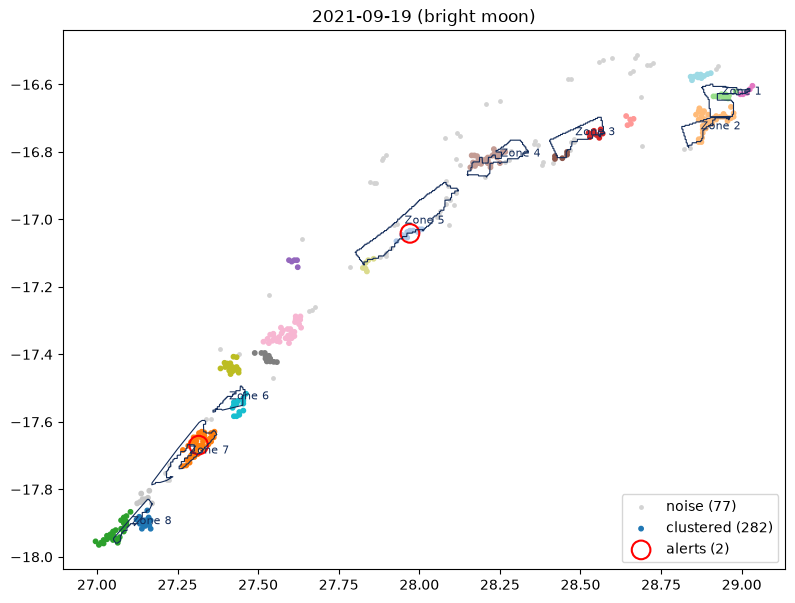

In [ ]:
test_points = points[points["Set"] == "test"]
if len(test_points):
    busiest = test_points.groupby("Date").size().idxmax()
    night = test_points[test_points["Date"] == busiest]
    fig, ax = plt.subplots(figsize=(10, 7))
    for zone in zones:
        ring = np.asarray(zone["boundary"]["coordinates"][0])
        ax.plot(ring[:, 0], ring[:, 1], color="#122B59", linewidth=0.8)
        ax.text(ring[:, 0].mean(), ring[:, 1].mean(), zone["name"], fontsize=8, color="#122B59")
    noise = night[night["Cluster_ID"] < 0]
    grouped = night[night["Cluster_ID"] >= 0]
    ax.scatter(noise["Longitude"], noise["Latitude"], s=6, color="lightgrey", label=f"noise ({len(noise)})")
    ax.scatter(grouped["Longitude"], grouped["Latitude"], s=10, c=grouped["Cluster_ID"], cmap="tab20", label=f"clustered ({len(grouped)})")
    flagged = alerts[alerts["Date"] == busiest]
    ax.scatter(flagged["Centroid_Lon"], flagged["Centroid_Lat"], s=180, facecolors="none", edgecolors="red", linewidths=1.5, label=f"alerts ({len(flagged)})")
    ax.set_aspect(1 / np.cos(np.radians(night["Latitude"].mean())))
    ax.set_title(f"{busiest.date()} ({moon_band(busiest)} moon)")
    ax.legend(loc="lower right")
    plt.show()

In [ ]:
   !cat ~/kariba-cleaning/model/kariba_model_settings.json
   !head -5 ~/kariba-cleaning/model/kariba_zone_baselines.csv

cat: /root/kariba-cleaning/model/kariba_model_settings.json: No such file or directory
head: cannot open '/root/kariba-cleaning/model/kariba_zone_baselines.csv' for reading: No such file or directory
